----

# 🚌🚌MOVILIDAD URBANA🚌🚌

### Introducción

El objetivo es evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas.
Para ello se trabaje con datos reales de TomTom Traffic Index y OECD Cities, se limpiaron, comninaron y analizo para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Se importaron las librerías necesarias, se cargo los archivos CSV en DataFrames y realizaron una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

traffic=pd.read_csv('/datasets/tomtom_traffic.csv')
eco=pd.read_csv('/datasets/oecd_city_economy.csv')
traffic.head()


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"



---

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

* ¿Hay columnas que requieren conversión?
* ¿Cuáles son?
* ¿Que tipo de dato tienen y cuál deberían de tener?
* ¿Hay datos ausentes en alguna columna?


In [ ]:
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

In [ ]:
#se muestra los primeros 3 renglones
traffic.head(3)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


In [ ]:
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


In [ ]:
#Se muestran los 3 primeros renglosnes
eco.head(3)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


In [ ]:
# Examinar la estructura de traffic
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

In [ ]:
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, ...
- En la estructura del DF eco, se observa que:
* Las columnas City GDP/capita y Unemployment % son de tipo object, aunque representan valores numéricos, por lo que deberían convertirse a tipo float64.
* Algunas columnas categóricas, como nombres de ciudades o países, están correctamente como tipo object.
* Se identifican posibles valores faltantes en algunas columnas, los cuales deberán tratarse en etapas posteriores del análisis.

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
traffic=traffic.rename(columns={'Country':'country',
                                'City':'city',
                                'UpdateTimeUTC':'update_time_utc',
                                'JamsDelay':'jams_delay',
                                'TrafficIndexLive':'traffic_index_live',
                                'JamsLengthInKms':'jams_length_in_kms',
                                'JamsCount':'jams_count',
                                'TrafficIndexWeekAgo':'traffic_index_week_ago',
                                'UpdateTimeUTCWeekAgo':'update_time_utc_week_ago',
                                'TravelTimeLivePer10KmsMins':'travel_time_live_per_10_kms_mins',
                                'TravelTimeHistoricPer10KmsMins':'travel_time_historic_per_10_kms_mins',
                                'MinsDelay':'mins_delay'})
#Verificar columnas
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10_kms_mins',
       'travel_time_historic_per_10_kms_mins', 'mins_delay'],
      dtype='object')

In [ ]:
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',  # ✅ Correcto
    'PM2.5 (μg/m³)': 'pm2_5_ug_m3',
    'Population (M)': 'population_m'       # ✅ Correcto
})

print("Columnas después del renombrado:")
print(eco.columns.tolist())

Columnas después del renombrado:
['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct', 'pm2_5_ug_m3', 'population_m']



### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.



In [ ]:
#1 Columna fecha de traffic cambiado a formato datetime
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')

# 2 Dataset eco limpieza de valores numéricos

eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '', regex=False)
eco['city_gdp_capita'] = eco['city_gdp_capita'].str.replace(',', '.', regex=False)
eco['city_gdp_capita'] = pd.to_numeric(eco['city_gdp_capita'], errors='coerce')

eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '', regex=False)
eco['unemployment_pct'] = eco['unemployment_pct'].str.replace(',', '.', regex=False)
eco['unemployment_pct'] = pd.to_numeric(eco['unemployment_pct'], errors='coerce')

eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.', regex=False)
eco['population_m'] = pd.to_numeric(eco['population_m'], errors='coerce')

#Nueva columna population
eco['population'] = (eco['population_m'] * 1000000).astype(int)

print("✅ Limpieza completada")

# Verificación
print(traffic.info())
print(eco.info())

✅ Limpieza completada
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                                Non-Null Count    Dtype         
---  ------                                --------------    -----         
 0   country                               1004464 non-null  object        
 1   city                                  1004464 non-null  object        
 2   update_time_utc                       1004464 non-null  datetime64[ns]
 3   jams_delay                            1004464 non-null  float64       
 4   traffic_index_live                    1004464 non-null  float64       
 5   jams_length_in_kms                    1004464 non-null  float64       
 6   jams_count                            1004464 non-null  float64       
 7   traffic_index_week_ago                1004464 non-null  float64       
 8   update_time_utc_week_ago              1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10_


---
## 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

In [ ]:
#Crear una columna year
traffic['year'] = traffic['update_time_utc'].dt.year

print(" Columna year creada")
print(f"Años únicos: {traffic['year'].unique()}")

# Filtrar para 2024 y crear copias independientes
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

print(f"✅ Registros en traffic_2024: {len(traffic_2024)}")
print(f"✅ Registros en eco_2024: {len(eco_2024)}")

 Columna year creada
Años únicos: [2025 2024]
✅ Registros en traffic_2024: 886779
✅ Registros en eco_2024: 15


In [ ]:
display(traffic_2024.head())
display(eco_2024.head())

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm2_5_ug_m3,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000



---

## 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.



In [ ]:
#Agrupacion city, country, year
traffic_city_year_2024 = traffic_2024.groupby(['city', 'country', 'year'])[[
    'jams_delay',
    'traffic_index_live',
    'jams_length_in_kms',
    'jams_count',
    'mins_delay',
    'travel_time_live_per_10_kms_mins',
    'travel_time_historic_per_10_kms_mins'
]].mean().reset_index()
#Promedio de metricas relevantes

# Ver resultado
print(traffic_city_year_2024.head())

        city country  year  jams_delay  traffic_index_live  \
0   a-coruna     ESP  2024   17.935187           15.259774   
1     aachen     DEU  2024   26.732141           20.960314   
2     aarhus     DNK  2024   21.200616           16.575891   
3  abu-dhabi     ARE  2024  171.157315           13.902028   
4      adana     TUR  2024   83.864761           22.541040   

   jams_length_in_kms  jams_count  mins_delay  \
0            2.198002    4.934405    0.774172   
1            3.892586    6.601832    0.792968   
2            2.736736    6.109987    0.495276   
3           24.507380   47.268019    0.139764   
4           11.827331   23.754620    1.129749   

   travel_time_live_per_10_kms_mins  travel_time_historic_per_10_kms_mins  
0                         16.267977                             15.493804  
1                         13.397861                             12.604894  
2                         15.219292                             14.724016  
3                          9


##Preguntas:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694



---

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.



In [ ]:
#Variables claves de traffic y eco usando .copy
traffic_sub = traffic_city_year_2024[['city','country','year','traffic_index_live','jams_delay']].copy()
eco_sub = eco[['year','city','country','city_gdp_capita','unemployment_pct']].copy()

#Union de ambos dataframes solo ciudades y año
merged = pd.merge(traffic_sub, eco_sub, on=['city', 'year'], how='inner')

#Guardado en variable, mostrando las primeras 5 filas
merged.head()

,city,country_x,year,traffic_index_live,jams_delay,country_y,city_gdp_capita,unemployment_pct
0,belo-horizonte,BRA,2024,19.428946,263.047879,Brazil,11124.0,9.5
1,bogota,COL,2024,37.614273,1141.552364,Colombia,11442.0,10.0
2,brasilia,BRA,2024,11.258220,101.576326,Brazil,16251.0,7.8
3,buenos-aires,ARG,2024,17.756012,571.089593,Argentina,18117.0,7.2
4,curitiba,BRA,2024,14.954545,183.469274,Brazil,12381.0,8.2



---

## 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

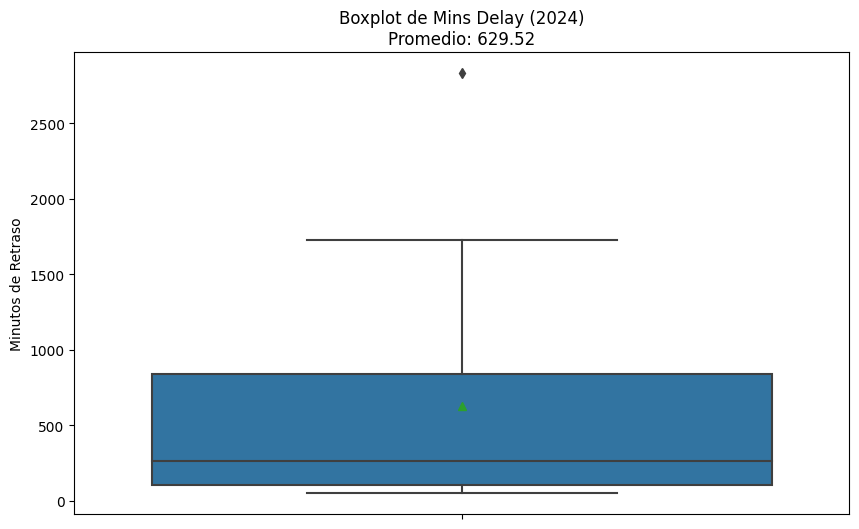

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestión
plt.figure(figsize=(10, 6))
sns.boxplot(data=merged, y='jams_delay', showmeans=True)

# Obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de Mins Delay (2024)\nPromedio: {mean_value:.2f}')
plt.ylabel('Minutos de Retraso')
plt.show()

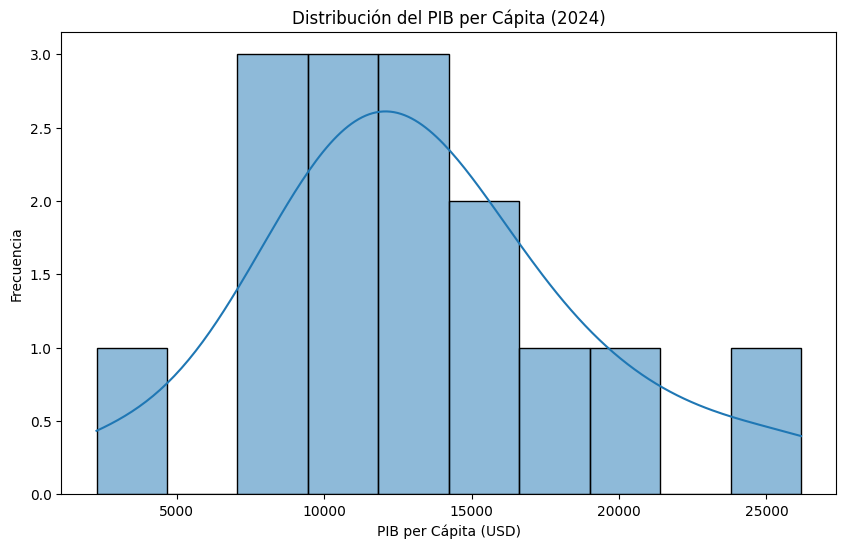

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.figure(figsize=(10, 6))
sns.histplot(data=merged, x='city_gdp_capita', kde=True, bins=10)
plt.title('Distribución del PIB per Cápita (2024)')
plt.xlabel('PIB per Cápita (USD)')
plt.ylabel('Frecuencia')
plt.show()

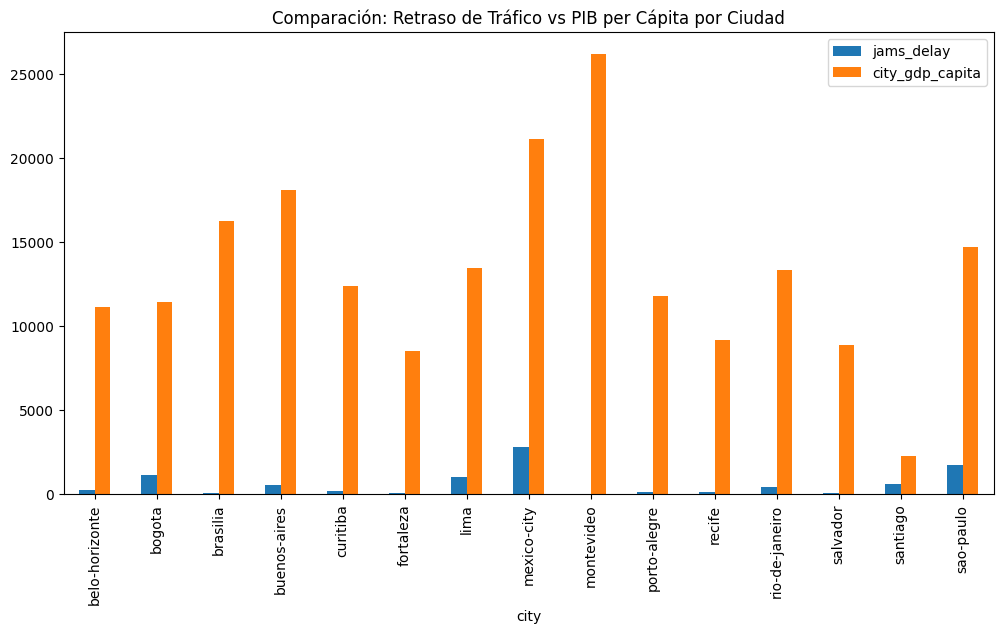

In [ ]:
# Gráfico de barras para comparar mins_delay y city_gdp_capita por ciudad
# Primero necesitas agrupar por ciudad para evitar duplicados
city_summary = merged.groupby('city').agg({
    'jams_delay': 'mean',
    'city_gdp_capita': 'mean'
}).reset_index()

city_summary.plot(x='city', y=['jams_delay', 'city_gdp_capita'], kind='bar', figsize=(12, 6))
plt.xticks(rotation=90)
plt.title('Comparación: Retraso de Tráfico vs PIB per Cápita por Ciudad')
plt.show()

In [1]:

Este análisis explora la relación entre movilidad urbana (medida por congestión y retraso promedio, jams_delay) y productividad económica (medida por PIB per cápita)
en 2024. Se busca entender cómo la congestión vehicular puede impactar la economía y priorizar inversiones en infraestructura de transporte.


'Este análisis explora la relación entre movilidad urbana (medida por congestión \ny retraso promedio, jams_delay) y productividad económica (medida por PIB per cápita) \nen 2024. Se busca entender cómo la congestión vehicular puede impactar la economía \ny priorizar inversiones en infraestructura de transporte.\n'